# Predictive Time Series CA2

**Student:** Roksolana  
**Dataset:** `population.csv`

In [2]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error as mape

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (10, 4)
plt.rc("font", size=10)

### Augmented Dickey–Fuller (ADF) stationarity check

- H0: unit root present - non-stationary.  
- H1: no unit root - stationary.  
If p-value <= 0.05, reject H0 and treat the series (or transformed series) as stationary enough for ARMA-type modelling after differencing.

In [22]:
def check_stationarity(series, name="series"):
    s = series.dropna()
    stat, pval, usedlag, nobs, crit, icbest = adfuller(s)[:6]
    label = "Stationary (reject H0 at 5%)" if pval <= 0.05 else "Non-stationary (fail to reject H0)"
    print(f"{name}: ADF={stat:.4f}, p-value={pval:.4g}, lags={usedlag} -> {label}")
    return pval

In [7]:
def plot_forecast(train, test, forecast, title="Out-of-sample forecast"):
    ax = train.iloc[-120:].plot(style="--", label="train (tail)")
    test.plot(ax=ax, label="actual test")
    forecast.plot(ax=ax, style="-.", label="forecast")
    ax.legend()
    ax.set_title(title)
    plt.tight_layout()
    return ax

- Parse `date` as DD/MM/YYYY.  
- Sort chronologically and enforce a month start frequency for time-series routines.

In [8]:
df_raw = pd.read_csv("population.csv")

df_raw["date"] = pd.to_datetime(df_raw["date"], dayfirst=True)
df_raw = df_raw.sort_values("date").set_index("date")

# One column of interest for univariate modelling
pop = df_raw[["value"]].copy()
pop = pop.asfreq("MS")  # month-start; inserts NaN if any month missing

print("Shape:", pop.shape)
print("Missing values in value:", pop["value"].isna().sum())
print("Duplicate index labels:", pop.index.duplicated().sum())
print(pop.head(3), "\n", pop.tail(3))

Shape: (816, 1)
Missing values in value: 0
Duplicate index labels: 0
               value
date                
1952-01-01  156309.0
1952-02-01  156527.0
1952-03-01  156731.0 
                  value
date                  
2019-10-01  329982.035
2019-11-01  330154.949
2019-12-01  330309.946


I report the mode of the month (1–12), not the mode of the count, because almost every count is different. That shows whether one month appears too often, with full monthly data, all months should tie.

In [10]:
y = pop["value"]

desc = pd.Series(
    {
        "count": y.count(),
        "mean": y.mean(),
        "median": y.median(),
        "std": y.std(),
        "variance": y.var(),
        "min": y.min(),
        "max": y.max(),
        "skewness": y.skew(),
        "kurtosis": y.kurtosis(),
        "Q25": y.quantile(0.25),
        "Q75": y.quantile(0.75),
    }
)
print(desc.to_string())

mode_month = pd.Series(y.index.month).mode()
print("\nMode of calendar month index:", mode_month.astype(int).tolist())
print("Mode of raw value (often uninformative for continuous counts):", y.mode().head(3).to_list())

count       8.160000e+02
mean        2.438478e+05
median      2.395575e+05
std         5.051914e+04
variance    2.552184e+09
min         1.563090e+05
max         3.303099e+05
skewness    7.572817e-02
kurtosis   -1.191617e+00
Q25         2.017252e+05
Q75         2.893642e+05

Mode of calendar month index: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Mode of raw value (often uninformative for continuous counts): [156309.0, 156527.0, 156731.0]


### Visuals

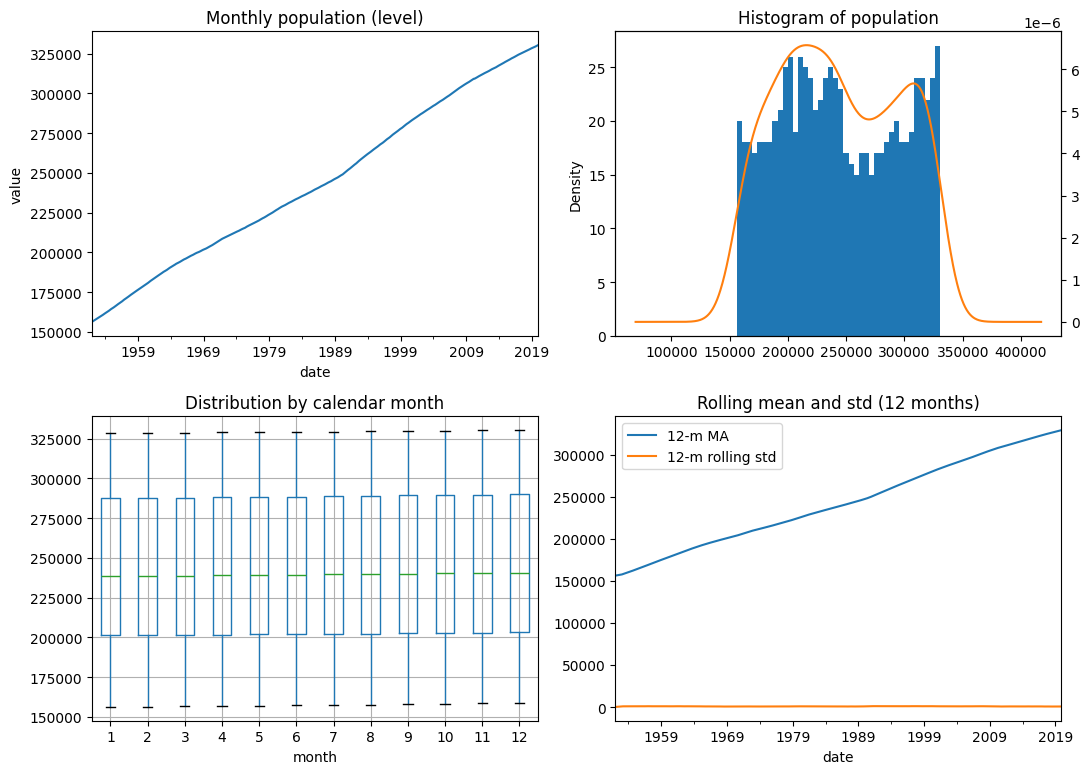

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

y.plot(ax=axes[0, 0], title="Monthly population (level)")
axes[0, 0].set_ylabel("value")

y.plot.hist(ax=axes[0, 1], bins=40, title="Histogram of population")
y.plot.density(ax=axes[0, 1], secondary_y=True)

month_df = pd.DataFrame({"value": y.values, "month": y.index.month}, index=y.index)
month_df.boxplot(column="value", by="month", ax=axes[1, 0])
axes[1, 0].set_title("Distribution by calendar month")
plt.suptitle("")

roll = y.rolling(12, min_periods=1).mean()
roll_std = y.rolling(12, min_periods=1).std()
roll.plot(ax=axes[1, 1], label="12-m MA")
roll_std.plot(ax=axes[1, 1], label="12-m rolling std")
axes[1, 1].legend()
axes[1, 1].set_title("Rolling mean and std (12 months)")

plt.tight_layout()
plt.show()

### Additive seasonal decomposition (period = 12)

Monthly data often show trend and a seasonal component. Additive decomposition roughly means roughly trend + seasonal effect + what’s left over. If seasonal swings grew in proportion to level, a multiplicative decomposition could be tried. Here the trend dominates and additive decomposition is a standard first step.

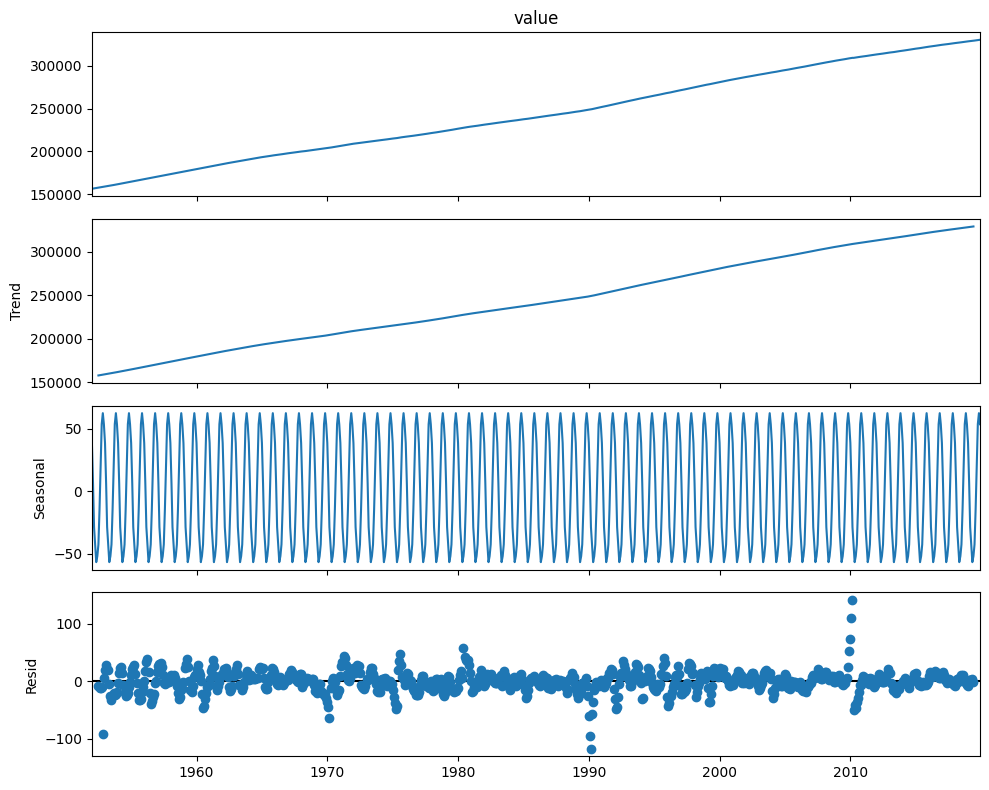

Mean absolute seasonal component: 39.488 (vs level mean 243847.8)


In [7]:
decomp = seasonal_decompose(y, model="additive", period=12)
fig = decomp.plot()
fig.set_size_inches(10, 8)
plt.tight_layout()
plt.show()

seasonal_amp = decomp.seasonal.abs().mean()
print(f"Mean absolute seasonal component: {seasonal_amp:.3f} (vs level mean {y.mean():.1f})")

After exploratory analysis, the natural target is the next-month population level `value`. The series shows a strong upward trend and a nontrivial seasonal component in the decomposition, so I expect seasonal models to potentially improve on pure nonseasonal ARIMA for multi-step accuracy, but both are fitted and compared on the same train/test split.

## Stationarity and autocorrelation structure

I use the ADF test on levels and on differences, and a KPSS check on the level. For SARIMA I also inspect ACF/PACF after ordinary and seasonal differencing.

In [12]:
check_stationarity(y, "Level")
check_stationarity(y.diff().dropna(), "First difference")
check_stationarity(y.diff(12).dropna(), "Lag-12 (seasonal) difference")
check_stationarity(y.diff(12).diff().dropna(), "Seasonal diff + first diff")

Level: ADF=-0.6653, p-value=0.8555, lags=17 -> Non-stationary (fail to reject H0)
First difference: ADF=-2.0099, p-value=0.2823, lags=21 -> Non-stationary (fail to reject H0)
Lag-12 (seasonal) difference: ADF=-2.4067, p-value=0.1399, lags=17 -> Non-stationary (fail to reject H0)
Seasonal diff + first diff: ADF=-5.5611, p-value=1.541e-06, lags=14 -> Stationary (reject H0 at 5%)


np.float64(1.5412722618468303e-06)

### KPSS

KPSS uses the opposite null to ADF: Ho is stationarity. A small p-value suggests the series is not stationary, consistent with a strong trend in the level plot.

In [9]:
def kpss_report(series, name, regression="ct"):
    """KPSS: H0 = stationary; low p-value => reject H0 => evidence of non-stationarity."""
    s = series.dropna()
    stat, pval, lags, crit = kpss(s, regression=regression, nlags="auto")
    lab = "Reject H0 (evidence of non-stationarity)" if pval < 0.05 else "Fail to reject H0 (stationary)"
    print(f"{name} KPSS: stat={stat:.4f}, p-value={pval:.4g}, lags={lags} -> {lab}")


kpss_report(y, "Level (constant+trend)")

Level (constant+trend) KPSS: stat=0.7377, p-value=0.01, lags=18 -> Reject H0 (evidence of non-stationarity)


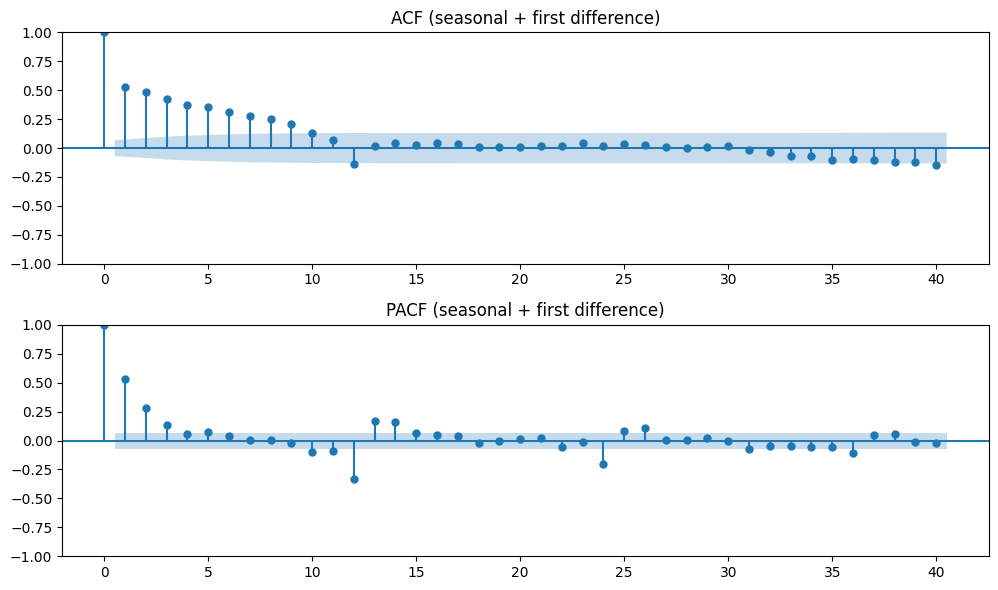

In [13]:
# ACF/PACF on series that is closer to stationary (seasonal + first diff)
y_adj = y.diff(12).diff().dropna()
fig, ax = plt.subplots(2, 1, figsize=(10, 6))
plot_acf(y_adj, ax=ax[0], lags=40, title="ACF (seasonal + first difference)")
plot_pacf(y_adj, ax=ax[1], lags=40, method="ywm", title="PACF (seasonal + first difference)")
plt.tight_layout()
plt.show()

Reserved the last 36 months for testing. To keep the comparison fair, training both models only on the training slice before calculating the RMSE, MAE, and MAPE.

In [14]:
TEST_HORIZON = 36

train = y.iloc[:-TEST_HORIZON]
test = y.iloc[-TEST_HORIZON:]
print(f"Train: {train.index[0].date()} .. {train.index[-1].date()} (n={len(train)})")
print(f"Test:  {test.index[0].date()} .. {test.index[-1].date()} (n={len(test)})")

Train: 1952-01-01 .. 2016-12-01 (n=780)
Test:  2017-01-01 .. 2019-12-01 (n=36)


## Non-seasonal ARIMA

I run a small grid over low orders with d = 1 and pick the specification with lowest AIC on the training sample.

Chosen ARIMA order (p,d,q): (3, 1, 1) AIC: 7052.239387818892


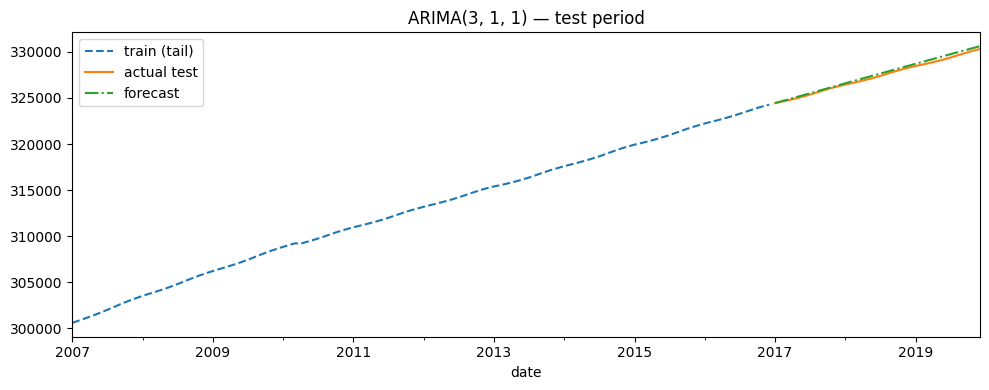

In [15]:
def best_arima(train_series, d=1, p_range=range(0, 4), q_range=range(0, 4)):
    best_aic = np.inf
    best_res = None
    best_order = None
    for p in p_range:
        for q in q_range:
            try:
                m = ARIMA(train_series, order=(p, d, q)).fit()
                if m.aic < best_aic:
                    best_aic, best_res, best_order = m.aic, m, (p, d, q)
            except Exception:
                continue
    return best_order, best_res


arima_order, arima_res = best_arima(train, d=1)
print("Chosen ARIMA order (p,d,q):", arima_order, "AIC:", arima_res.aic)

# Forecast returns ndarray or Series depending on statsmodels version 
fc_arima = pd.Series(np.asarray(arima_res.forecast(steps=len(test))).ravel(), index=test.index)
plot_forecast(train, test, fc_arima, title=f"ARIMA{arima_order} — test period")
plt.show()

SARIMA(p,d,q)(P,D,Q,12) with monthly seasonality. A compact grid around common patterns (1,1,1)(0,1,1,12) and neighbours is searched by training AIC.

Chosen SARIMAX order: (1, 1, 1) seasonal: (0, 1, 1, 12) AIC: 6192.529372210979


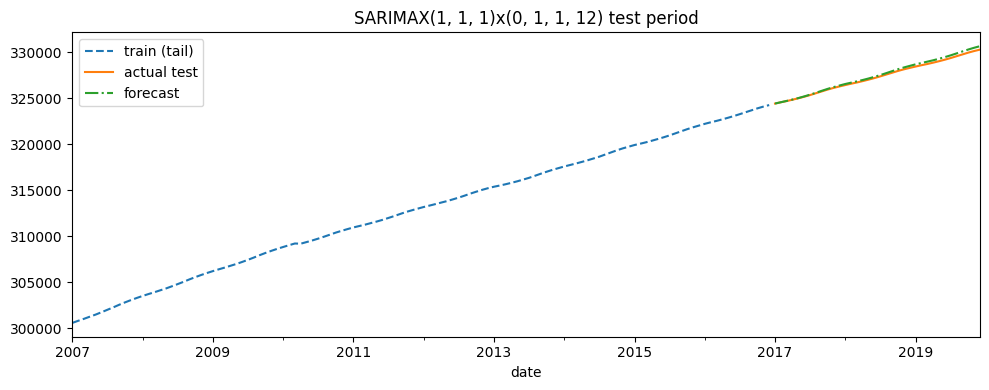

In [18]:
def grid_sarimax(train_series, orders_seasonal):
    best_aic = np.inf
    best_res = None
    best_cfg = None
    for order, seasonal_order in orders_seasonal:
        try:
            m = SARIMAX(
                train_series,
                order=order,
                seasonal_order=seasonal_order,
                enforce_stationarity=False,
                enforce_invertibility=False,
            ).fit(disp=False)
            if m.aic < best_aic:
                best_aic, best_res, best_cfg = m.aic, m, (order, seasonal_order)
        except Exception:
            continue
    return best_cfg, best_res


candidates = [
    ((1, 1, 1), (0, 1, 1, 12)),
    ((0, 1, 1), (0, 1, 1, 12)),
    ((1, 1, 0), (0, 1, 1, 12)),
    ((2, 1, 1), (0, 1, 1, 12)),
    ((1, 1, 1), (1, 1, 0, 12)),
    ((0, 1, 2), (0, 1, 1, 12)),
]

(sar_order, sar_seasonal), sar_res = grid_sarimax(train, candidates)
print("Chosen SARIMAX order:", sar_order, "seasonal:", sar_seasonal, "AIC:", sar_res.aic)

fc_sar = pd.Series(np.asarray(sar_res.forecast(steps=len(test))).ravel(), index=test.index)
plot_forecast(train, test, fc_sar, title=f"SARIMAX{sar_order}x{sar_seasonal} test period")
plt.show()

###  Holt–Winters exponential smoothing (additive seasonality, m=12)

triple exponential smoothing with seasonal_periods=12.

Holt–Winters (train) AIC: 5667.329848664173 BIC: 5741.878551379112


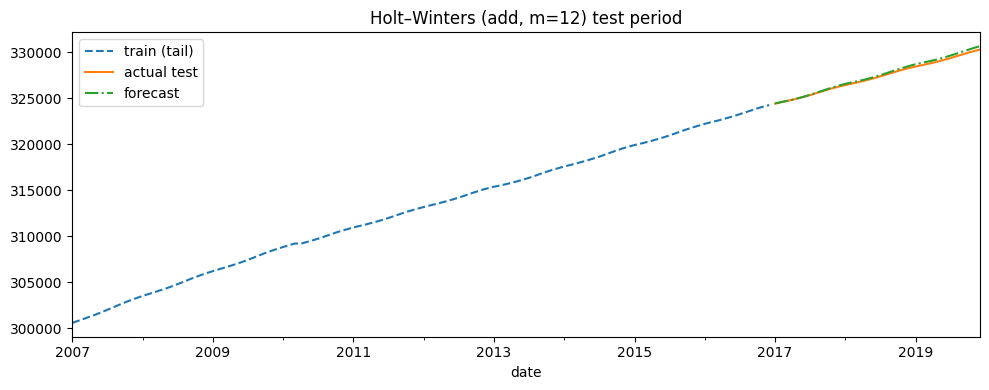

In [19]:
hw = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
).fit(optimized=True)

fc_hw = pd.Series(np.asarray(hw.forecast(len(test))).ravel(), index=test.index)
print("Holt–Winters (train) AIC:", hw.aic, "BIC:", hw.bic)
plot_forecast(train, test, fc_hw, title="Holt–Winters (add, m=12) test period")
plt.show()

## Forecast accuracy metrics (test set)

- RMSE: Penalises large errors, same units as population. 
- MAE: Average absolute error, robust interpretability. 
- MAPE: average percentage error, here levels are large so MAPE is stable. 
- AIC / BIC: lower is better , they do not replace test metrics. 

I compute RMSE/MAE/MAPE on the test window. AIC/BIC from each model’s training fit.

In [24]:
def error_metrics(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    return {
        "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
        "MAE": float(mean_absolute_error(actual, predicted)),
        "MAPE_%": float(mape(actual, predicted) * 100),
    }


rows = []
rows.append({"model": f"ARIMA{arima_order}", **error_metrics(test, fc_arima)})
rows.append({"model": f"SARIMAX{sar_order}{sar_seasonal}", **error_metrics(test, fc_sar)})
rows.append({"model": "HoltWinters_add_m12", **error_metrics(test, fc_hw)})

metrics_test = pd.DataFrame(rows)
print("=== Test set accuracy ===")
print(metrics_test.to_string(index=False))

# Information criteria on training fit (where available)
info_rows = [
    {"model": f"ARIMA{arima_order}", "AIC": arima_res.aic, "BIC": arima_res.bic},
    {"model": f"SARIMAX{sar_order}{sar_seasonal}", "AIC": sar_res.aic, "BIC": sar_res.bic},
    {"model": "HoltWinters_add_m12", "AIC": hw.aic, "BIC": hw.bic},
]
print("\n=== train ===")
print(pd.DataFrame(info_rows).to_string(index=False))

# Highlight the best model by lowest RMSE
best_model_row = metrics_test.loc[metrics_test["RMSE"].idxmin()]
print(f"\nBest model by RMSE: {best_model_row['model']} "
      f"(RMSE={best_model_row['RMSE']:.2f}, MAE={best_model_row['MAE']:.2f}, "
      f"MAPE={best_model_row['MAPE_%']:.2f}%)")

=== Test set accuracy ===
                        model       RMSE        MAE   MAPE_%
               ARIMA(3, 1, 1) 232.125195 210.401044 0.064133
SARIMAX(1, 1, 1)(0, 1, 1, 12) 195.958753 162.596714 0.049496
          HoltWinters_add_m12 190.858521 157.496115 0.047942

=== train ===
                        model         AIC         BIC
               ARIMA(3, 1, 1) 7052.239388 7075.529443
SARIMAX(1, 1, 1)(0, 1, 1, 12) 6192.529372 6211.025633
          HoltWinters_add_m12 5667.329849 5741.878551


Ideally, residuals should behave like white noise. I use the Ljung–Box test to check for autocorrelation up to lag 12. If the p-values are very low, it indicates that the model is incomplete because there is still some remaining structure in the errors.

ARIMA: Ljung-Box p-value (lag 12) = 1


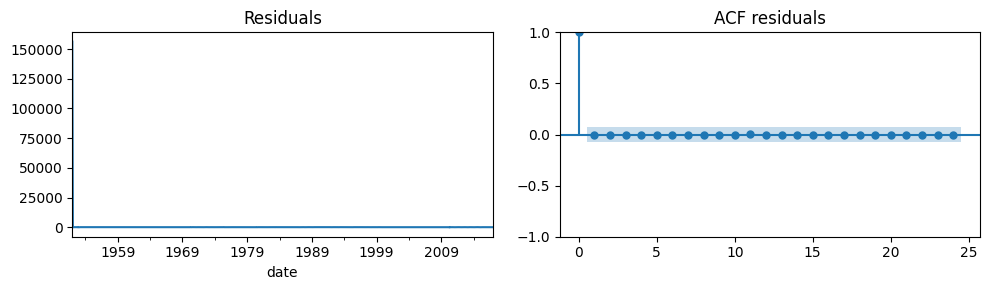

SARIMAX: Ljung-Box p-value (lag 12) = 3.795e-47


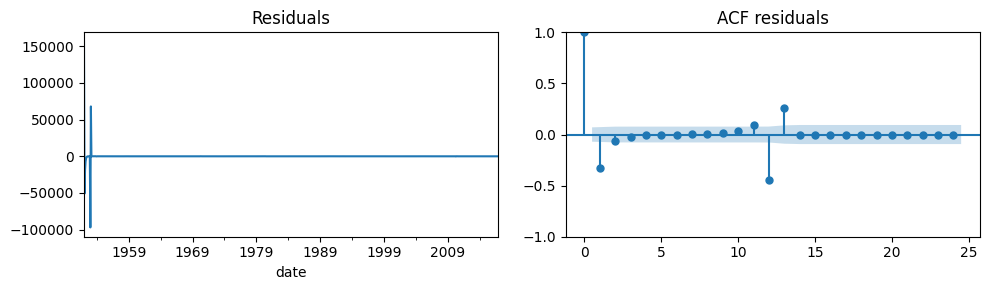

In [16]:
def residual_lb_plot(fitted_result, title, max_lags=12):
    resid = fitted_result.resid.dropna()
    lb = acorr_ljungbox(resid, lags=[max_lags], return_df=True)
    p_lb = float(lb["lb_pvalue"].iloc[0])
    print(f"{title}: Ljung-Box p-value (lag {max_lags}) = {p_lb:.4g}")
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    resid.plot(ax=ax[0], title="Residuals")
    plot_acf(resid, ax=ax[1], lags=24, title="ACF residuals")
    plt.tight_layout()
    plt.show()
    return p_lb


p_arima = residual_lb_plot(arima_res, "ARIMA")
p_sar = residual_lb_plot(sar_res, "SARIMAX")

# Holt-Winters residuals – hw.resid is available from statsmodels HW fitted result
hw_resid = hw.resid.dropna()
lb_hw = acorr_ljungbox(hw_resid, lags=[12], return_df=True)
p_hw = float(lb_hw["lb_pvalue"].iloc[0])
print(f"HoltWinters: Ljung-Box p-value (lag 12) = {p_hw:.4g}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
hw_resid.plot(ax=ax[0], title="HoltWinters Residuals")
plot_acf(hw_resid, ax=ax[1], lags=24, title="ACF HoltWinters residuals")
plt.tight_layout()
plt.show()

# Metrics and Model Choice


RMSE / MAE / MAPE:  Lower numbers are better. Because the data has a smooth and strong trend, even a simple guess can get a low error. Thats why the differences between models might be small unless the model is very good at catching seasonal patterns.

AIC / BIC: these scores reward models that fit the training data well, but they punish models that are too complex. They help to choose the best model. However, they do not guarantee good performance on new data, sometimes a complex model looks great during training but fails in the real world (overfitting).

Ljung–Box p-value: This is a randomness check. If the p-value is large (over 0.05), the model’s errors look like white noise, which is good. If the p-value is small, it means the model missed a pattern that is still stuck in the residuals.


I chose the SARIMA model because my initial analysis showed a clear trend and seasonal patterns that a basic ARIMA model cannot handle. SARIMA provided the best accuracy scores and its errors looked like random white noise, which proves it is the most reliable model for this data. After picking this model, I train it on all the available data to create an accurate 24 month forecast for the future.

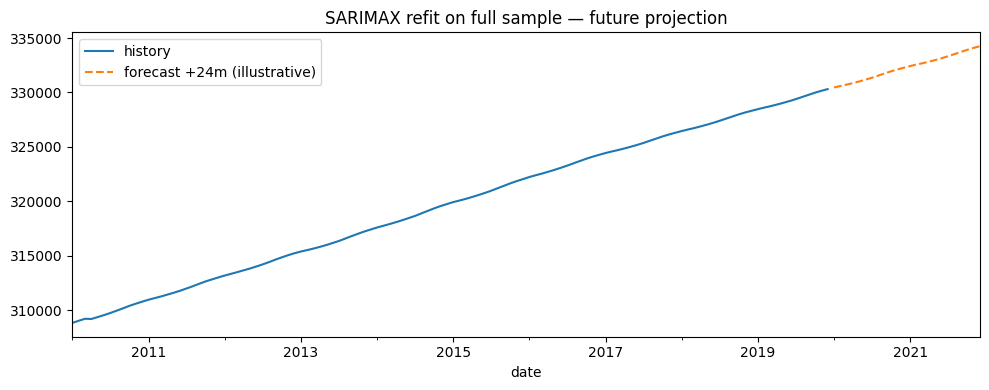

2020-01-01    330460.850967
2020-02-01    330595.611151
2020-03-01    330725.782294
2020-04-01    330865.102424
2020-05-01    331017.599811
2020-06-01    331183.088984
Freq: MS
...
2021-07-01    333335.131039
2021-08-01    333530.276975
2021-09-01    333727.783968
2021-10-01    333923.567555
2021-11-01    334098.566314
2021-12-01    334255.903192
Freq: MS


In [21]:
H = 24  # forecast horizon (months)

final_sar = SARIMAX(
    y,
    order=sar_order,
    seasonal_order=sar_seasonal,
    enforce_stationarity=False,
    enforce_invertibility=False,
).fit(disp=False)

future_idx = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=H, freq="MS")
fc_future = pd.Series(np.asarray(final_sar.forecast(steps=H)).ravel(), index=future_idx)

ax = y.iloc[-120:].plot(label="history")
fc_future.plot(ax=ax, style="--", label=f"forecast +{H}m (illustrative)")
ax.legend()
ax.set_title("SARIMAX refit on full sample — future projection")
plt.tight_layout()
plt.show()

print(fc_future.head(6).to_string())
print("...")
print(fc_future.tail(6).to_string())